# Numpy (phần 2)

**Reference**
1. [Python Data Science Handbook
](https://jakevdp.github.io/PythonDataScienceHandbook/02.00-introduction-to-numpy.htm)
2. [Numpy cheat sheet](https://www.datacamp.com/cheat-sheet/numpy-cheat-sheet-data-analysis-in-python)

## 0. Setup

In [3]:
import math
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
np.set_printoptions(suppress=True, precision=4)   # easier-to-read output

grades = np.genfromtxt("Data/P4DS-Grades.csv", delimiter=",", skip_header=1)
X_grades = grades[:, :4]          # HW1, HW2, HW3, Project
official = grades[:, 4]           # published final grade
weights = np.array([0.5 / 3, 0.5 / 3, 0.5 / 3, 0.5])
X_grades.shape

(45, 4)

## 1. Broadcasting

Là cơ chế của Numpy cho phép thực hiện tính toán khi các array không có cùng shape như thể có cùng shape (ở bên dưới, vụ này sẽ được thực hiện một cách hiệu quả: sẽ không tạo ra các array mới có cùng shape).

Ví dụ: 

`a = np.array([1, 2, 3])`

`a + 10`

[Luật broadcasting](https://numpy.org/devdocs/user/quickstart.html#broadcasting-rules):

1. Nếu hai mảng có số chiều khác nhau, thêm các số 1 vào **bên trái** shape ngắn hơn.
2. Ở mỗi chiều, kích thước phải **bằng nhau**, hoặc một trong hai phải bằng **1**. Chiều có kích thước 1 sẽ được kéo giãn cho khớp.
3. Nếu không thỏa: báo lỗi.

In [4]:
#Ví dụ 1: 1D + 2D
M = np.ones((2, 3))
a = np.arange(3)
print(f'{M.shape}\n{a.shape}')

(2, 3)
(3,)


In [5]:
M+a

array([[1., 2., 3.],
       [1., 2., 3.]])

Shape của hai mảng là:

- ``M.shape = (2, 3)``
- ``a.shape = (3,)``

Với rule 1: a có ít chiều hơn, nên sẽ được pad vào bên trái:

- ``M.shape -> (2, 3)``
- ``a.shape -> (1, 3)``

Với rule 2, chiều thứ nhất của `a`sẽ được lặp lại để khớp với `M`:

- ``M.shape -> (2, 3)``
- ``a.shape -> (2, 3)``

Shape của kết quả sẽ là ``(2, 3)``:

In [6]:
# Ví dụ 2
a = np.array([[4, 5, 6],
              [7, 8, 9]])
a.shape

(2, 3)

In [7]:
a + 10

array([[14, 15, 16],
       [17, 18, 19]])

In [8]:
# Ví dụ 3
a = np.array([[4, 5, 6],
              [7, 8, 9]])
b = np.array([1, 2, 3])
print(f'{a.shape}\n{b.shape}')

(2, 3)
(3,)


In [9]:
a * b

array([[ 4, 10, 18],
       [ 7, 16, 27]])

In [10]:
# Broadcasting - ví dụ 4
a = np.array([[4],
              [5],
              [6]])
b = np.array([1, 2, 3])
print(f'{a.shape}\n{b.shape}')

(3, 1)
(3,)


In [11]:
a + b

array([[5, 6, 7],
       [6, 7, 8],
       [7, 8, 9]])

In [12]:
# Broadcasting - ví dụ 5
a = np.array([[4, 5, 6],
              [7, 8, 9]])
b = np.array([1, 2])
print(f'{a.shape}\n{b.shape}')

(2, 3)
(2,)


In [13]:
a * b

ValueError: operands could not be broadcast together with shapes (2,3) (2,) 

### 1.1 Ứng dụng trong khoa học dữ liệu: chuẩn hóa từng cột

$z = \dfrac{x - \text{mean}}{\text{std}}$ cho **từng cột**, để mọi đặc trưng (feature) có cùng thang đo.

In [14]:
mu = X_grades.mean(axis=0)        # shape (4,)
sd = X_grades.std(axis=0)         # shape (4,)
Z = (X_grades - mu) / sd          # (45, 4) - (4,) -> (45, 4)

print("mean của các cột:", Z.mean(axis=0))      # không đúng bằng 0! (Phần 3)
print("std của các cột :", Z.std(axis=0))

assert np.allclose(Z.mean(axis=0), 0) and np.allclose(Z.std(axis=0), 1)

mean của các cột: [ 0.  0.  0. -0.]
std của các cột : [1. 1. 1. 1.]


### 1.2 Lỗi broadcasting "im lặng"

Shape `(n,)` và `(n, 1)` trông như "cùng một vector". Broadcast hai mảng này với nhau tạo ra một **ma trận n×n**, và không có lỗi nào được báo.

Tình huống thường gặp: mô hình trả về dự đoán dạng cột `(n, 1)`, còn nhãn thật có shape `(n,)`.

In [15]:
y_true = official                              # (45,)
y_pred = X_grades @ weights.reshape(-1, 1)     # (45, 4) @ (4, 1) -> (45, 1)

mse_buggy = np.mean((y_true - y_pred) ** 2)
print("MSE bị lỗi:", mse_buggy, "| shape của hiệu:", (y_true - y_pred).shape)

mse = np.mean((y_true - y_pred.ravel()) ** 2)
print("MSE đúng  :", mse)

MSE bị lỗi: 6.5711410699588475 | shape của hiệu: (45, 45)
MSE đúng  : 7.407407407407848e-06


## 2 Áp dụng Numpy và broadcast để làm một ví dụ thực tế: k-Nearest Neighbors

In [16]:
# Generate sample data
X_train = np.random.rand(10, 2) * 10  # 10 training points
X_test = np.random.rand(5, 2) * 10    # 5 test points

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)
print("\nFirst 3 training points:\n", X_train[:3])
print("\nFirst 2 test points:\n", X_test[:2])

Training data shape: (10, 2)
Test data shape: (5, 2)

First 3 training points:
 [[9.1681 2.4681]
 [8.2805 4.4336]
 [9.0321 2.4885]]

First 2 test points:
 [[1.9435 5.7225]
 [3.7432 6.8898]]


### Visualize the Data

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c='blue', s=100, alpha=0.6, label='Training points')
plt.scatter(X_test[:, 0], X_test[:, 1], c='red', s=150, marker='*', label='Test points')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Training and Test Points')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<Figure size 800x600 with 1 Axes>

### Approach 1 - Using Loops (Intuitive but Slow)
Trước tiên, hãy cài đặt KNN theo cách "hiển nhiên" bằng các vòng lặp lồng nhau. Cách này dễ hiểu nhưng không hiệu quả.

In [18]:
def knn_with_loops(X_train, X_test, k=3):
    """
    KNN implementation using nested loops.
    
    For each test point:
        For each training point:
            Calculate distance
        Find k smallest distances
    """
    n_test = X_test.shape[0]
    n_train = X_train.shape[0]
    
    # Store indices of k nearest neighbors for each test point
    neighbors = np.zeros((n_test, k), dtype=int)
    
    # For each test point
    for i in range(n_test):
        distances = np.zeros(n_train)
        
        # Calculate distance to each training point
        for j in range(n_train):
            # Euclidean distance: sqrt((x1-x2)^2 + (y1-y2)^2)
            diff = X_test[i] - X_train[j]
            distances[j] = np.sqrt(np.sum(diff ** 2))
        
        # Find indices of k smallest distances
        neighbors[i] = np.argsort(distances)[:k]
    
    return neighbors

# Test it
k = 3
start = time.time()
neighbors_loop = knn_with_loops(X_train, X_test, k)
time_loop = time.time() - start

print(f"Time taken (loops): {time_loop:.6f} seconds")
print(f"\nFor each test point, the {k} nearest training points are:")
print(neighbors_loop)

Time taken (loops): 0.000763 seconds

For each test point, the 3 nearest training points are:
[[3 8 4]
 [3 8 7]
 [6 4 3]
 [6 4 3]
 [6 4 2]]


#### Visualize Results

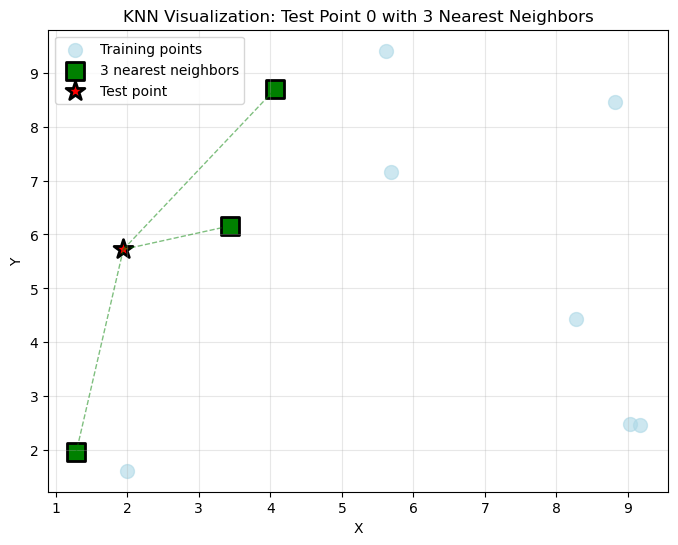

In [19]:
# Visualize neighbors for the first test point
test_idx = 0
neighbor_indices = neighbors_loop[test_idx]

plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c='lightblue', s=100, alpha=0.6, label='Training points')
plt.scatter(X_train[neighbor_indices, 0], X_train[neighbor_indices, 1], 
            c='green', s=150, marker='s', label=f'{k} nearest neighbors', edgecolors='black', linewidths=2)
plt.scatter(X_test[test_idx, 0], X_test[test_idx, 1], 
            c='red', s=200, marker='*', label='Test point', edgecolors='black', linewidths=2)

# Draw lines to nearest neighbors
for idx in neighbor_indices:
    plt.plot([X_test[test_idx, 0], X_train[idx, 0]], 
             [X_test[test_idx, 1], X_train[idx, 1]], 
             'g--', alpha=0.5, linewidth=1)

plt.xlabel('X')
plt.ylabel('Y')
plt.title(f'KNN Visualization: Test Point 0 with {k} Nearest Neighbors')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Cách tiếp cận 2: Vector hóa

#### Ma trận khoảng cách

Ý tưởng chính: Chúng ta muốn tính TẤT CẢ các khoảng cách theo từng cặp cùng một lúc!

Ta cần một ma trận khoảng cách `D` sao cho:
- `D[i, j]` = khoảng cách giữa điểm kiểm tra `i` và điểm huấn luyện `j`
- Kích thước của `D` = `(n_test, n_train)`

**Câu hỏi:** Làm thế nào để tính ma trận này mà không dùng vòng lặp?

#### Intuition

In [ ]:
s1 = np.array(['1','2'])
s2 = np.array(['-1','-2','-3'])
s1.reshape(-1,1) + s2

In [ ]:
def knn_vectorized(X_train, X_test, k=3):
    """
    Vectorized KNN using broadcasting with np.newaxis.
    
    Key steps:
    1. Expand dimensions for broadcasting
    2. Compute all pairwise differences at once
    3. Calculate distances
    4. Find k nearest for each test point
    """
    # Shape: (n_test, 1, 2) - (n_train, 2) -> (n_test, n_train, 2)
    differences = X_test.reshape(-1,1,2) - X_train
    
    # Square and sum over last axis
    squared_distances = np.sum(differences ** 2, axis=2)  # (n_test, n_train)
    
    # Take square root (optional: can use squared distances for comparison)
    distances = np.sqrt(squared_distances)
    
    # Find k nearest neighbors for each test point
    # argsort gives indices that would sort the array
    neighbors = np.argsort(distances, axis=1)[:, :k]
    
    return neighbors

# Test it
start = time.time()
neighbors_vec1 = knn_vectorized(X_train, X_test, k)
time_vec1 = time.time() - start

print(f"Time taken (vectorized): {time_vec1:.6f} seconds")
print(f"Speedup: {time_loop/time_vec1:.2f}x\n")
print("Neighbors (vectorized):")
print(neighbors_vec1)
print("\nNeighbors (loops):")
print(neighbors_loop)
print("\nResults match:", np.array_equal(neighbors_vec1, neighbors_loop))

### So sánh hiệu năng

Hãy thử nghiệm với các tập dữ liệu lớn hơn để thấy rõ sự khác biệt thực sự về hiệu năng.

In [ ]:
# Generate larger datasets
sizes = [50, 100, 200, 500]
results = {'size': [], 'loop': [], 'vectorized': [], 'speedup': []}

for size in sizes:
    X_train_large = np.random.rand(size, 2) * 10
    X_test_large = np.random.rand(size // 5, 2) * 10
    
    # Loop version
    start = time.time()
    knn_with_loops(X_train_large, X_test_large, k=5)
    time_loop = time.time() - start
    
    # Vectorized version
    start = time.time()
    knn_vectorized(X_train_large, X_test_large, k=5)
    time_vec = time.time() - start
    
    results['size'].append(size)
    results['loop'].append(time_loop)
    results['vectorized'].append(time_vec)
    results['speedup'].append(time_loop / time_vec)
    
    print(f"Size {size:3d} | Loop: {time_loop:.4f}s | Vectorized: {time_vec:.4f}s | Speedup: {time_loop/time_vec:.1f}x")

## 3. Các lỗi thường gặp của số thực dấu chấm động (floating point)
Một số `float64` lưu giá trị ở dạng nhị phân với **52 bit phần định trị**, tương đương khoảng 15–16 chữ số thập phân có nghĩa. Hầu hết các phân số thập phân (0.1, 0.2, 8.19…) **không biểu diễn chính xác được ở hệ nhị phân**, nên được lưu bằng giá trị gần nhất có thể biểu diễn.

### 3.1 Ví dụ nổi tiếng

In [ ]:
print(0.1 + 0.2 == 0.3)
print(f"{0.1:.20f}")
print(f"{0.2:.20f}")
print(f"{0.1 + 0.2:.20f}")
print(f"{0.3:.20f}")

### 3.2 Lỗi ở khi làm tròn

Hàm `parse_price` của một bạn trong nhóm biến `"8,19 triệu"` thành 8.189.999 đồng:

In [22]:
print(8.19 * 1_000_000)
print(int(8.19 * 1_000_000))      # int() cắt bỏ phần thập phân (làm tròn về phía 0)
print(round(8.19 * 1_000_000))    # round() làm tròn đến số nguyên gần nhất

8189999.999999999
8189999
8190000


**Quy tắc với tiền:** đổi sang số đồng nguyên bằng `round`, rồi giữ ở dạng **số nguyên**. Không bao giờ cộng tiền bằng số thực.

### 3.3 So sánh với sai số cho phép, không dùng `==`

Ở Demo trong bài `6`: điểm ta tính ra chỉ khớp với điểm chính thức 12/45 lần khi so bằng `==`.

In [ ]:
final = X_grades @ weights
print("==        :", (final == official).sum())
print("isclose   :", np.isclose(final, official).sum(), " (mặc định rtol=1e-05, atol=1e-08)")
print("atol=0.005:", np.isclose(final, official, atol=0.005).sum())

`np.isclose(a, b)` kiểm tra $|a - b| \le \text{atol} + \text{rtol}\cdot|b|$.
- **`atol`** (sai số tuyệt đối) quan trọng khi giá trị gần 0 và khi bạn biết độ chính xác của dữ liệu: điểm đã được làm tròn 2 chữ số thập phân, nên chênh lệch đến 0.005 là bình thường.
- **`rtol`** (sai số tương đối) tăng theo độ lớn của các số.

Chọn sai số cho phép **dựa vào dữ liệu**, không chọn bừa.

Khi lọc dữ liệu cũng gặp vấn đề tương tự:

In [ ]:
row = 2
print("điểm chính thức của dòng 2:", official[row], 
      "| điểm tính được:", final[row])
print("final == 8.21          :", (final == 8.21).sum(), "sinh viên")
print("isclose(final, 8.21, atol=0.005):", 
      np.isclose(final, 8.21, atol=0.005).sum(), "sinh viên")

### 3.4 Thứ tự rất quan trọng: số lớn + số nhỏ, và phép tính tổng

Cộng hai số có độ lớn chênh lệch nhiều sẽ làm mất số nhỏ. Vì vậy phép cộng số thực **không có tính kết hợp**: thứ tự cộng làm thay đổi kết quả.

In [ ]:
a = 0.1
b = 0.2
c = 0.3

print((a + b) + c)   # 0.6000000000000001
print(a + (b + c))   # 0.6

print((a + b) + c == a + (b + c))   # False

In [ ]:
print(1e16 + 1 == 1e16)                    # số 1 bị mất
print((1e16 + 1) - 1e16, "và", (1e16 - 1e16) + 1)

In [ ]:
vals = [0.1] * 10

total = 0.0
for v in vals:                 # vòng lặp cộng dồn từ trái sang phải
    total += v
print("vòng lặp   :", repr(total))
print("sum()      :", repr(sum(vals)))           # Python 3.12+ dùng phép cộng có bù sai số (compensated summation)
print("np.sum     :", repr(np.sum(vals)))        # cộng theo cặp (pairwise summation)
print("math.fsum  :", repr(math.fsum(vals)))     # làm tròn chính xác

many = [0.1] * 1_000_000
print("\n1.000.000 x 0.1:")
total = 0.0
for v in many:
    total += v
print("vòng lặp   :", repr(total))
print("np.sum     :", repr(np.sum(many)))
print("math.fsum  :", repr(math.fsum(many)))

Các thuật toán khác nhau cho kết quả hơi khác nhau, và tất cả đều "đúng" trong phạm vi sai số của số thực. Đó là lý do hai chương trình đúng có thể in ra vài chữ số cuối khác nhau, và vì sao kiểm thử phải dùng sai số cho phép.

### 3.5 Triệt tiêu thảm khốc (catastrophic cancellation)

Trừ hai số lớn **gần bằng nhau** sẽ xóa sạch các chữ số có nghĩa.

**Ví dụ 1: công thức phương sai trong sách giáo khoa.** $\operatorname{Var}(x) = E[x^2] - E[x]^2$ đúng về mặt đại số, nhưng tính toán rất tệ khi các giá trị lớn và sát nhau, ví dụ mốc thời gian Unix (khoảng $1.7\times10^9$ giây) hoặc giá tiền tính bằng đồng.

In [ ]:
timestamps = 1.7e9 + rng.normal(0, 1, 1_000)       # các sự kiện cách nhau khoảng 1 giây

var_textbook = np.mean(timestamps ** 2) - np.mean(timestamps) ** 2
print("sách giáo khoa E[x^2] - E[x]^2:", var_textbook)
print("np.var (hai lượt)             :", np.var(timestamps))
print("trừ trung bình trước rồi bình phương:", np.var(timestamps - timestamps.mean()))

$x^2 \approx 2.9\times10^{18}$, và ở độ lớn đó hai số float64 liền kề cách nhau 512. Phương sai thật (≈1) biến mất. `np.var` trừ trung bình **trước**, rồi mới bình phương các số nhỏ.

**Ví dụ 2: công thức tính khoảng cách “nhanh”**

**Nhắc lại**: để tính bình phương khoảng cách Euclid giữa mọi cặp điểm trong hai tập điểm, có hai cách:

**Cách 1**: trực tiếp, lấy hiệu từng tọa độ rồi bình phương:

$$\lVert a - b\rVert^2 = \sum_j (a_j - b_j)^2$$

Cho hai tập điểm: `A` gồm `n` điểm, `B` gồm `m` điểm, mỗi điểm có `d` tọa độ (đặc trưng). Tức là `A` có shape `(n, d)` và `B` có shape `(m, d)`. Kết quả là ma trận `(n, m)`: phần tử `[i, j]` là bình phương khoảng cách từ điểm `i` của `A` đến điểm `j` của `B`.
```python
# (n, 1, d) - (1, m, d) -> (n, m, d) -> (n, m)
d2_exact = ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1)   
```

Dễ hiểu, nhưng phải tạo một mảng trung gian shape (n, m, d). Với n = m = 20.000 điểm và d = 4 đặc trưng, mảng này cần khoảng 12,8 GB bộ nhớ.

**Cách 2**: khai triển bình phương, giống hằng đẳng thức $(a - b)^2 = a^2 + b^2 - 2ab$:

$$\lVert a - b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a\cdot b$$

```python
sq_A = (A ** 2).sum(axis=1) # ‖a‖² của mỗi điểm, shape (n,)
sq_B = (B ** 2).sum(axis=1) # ‖b‖² của mỗi điểm, shape (m,)
d2_fast = sq_A[:, None] + sq_B[None, :] - 2 * A @ B.T   
# (n, 1) + (1, m) - (n, m) -> (n, m)
```

Chỉ cần ma trận kết quả `(n, m)` và một phép nhân ma trận (`A @ B.T` tính mọi tích vô hướng $a\cdot b$ cùng lúc), nên nhanh hơn và tốn ít bộ nhớ hơn nhiều. Các thư viện như scikit-learn dùng cách này.

Về mặt toán học, hai cách cho kết quả như nhau. Nhưng khi tính trên máy, cách 2 có một điểm yếu: nó cộng ba số lớn rồi trừ cho nhau. Nếu các điểm nằm xa gốc tọa độ, $\lVert a\rVert^2$, $\lVert b\rVert^2$ và $2a\cdot b$ đều rất lớn và gần bằng nhau, nên phép trừ gây ra triệt tiêu thảm khốc, giống công thức phương sai ở Ví dụ 1. Ô code dưới đây minh họa điều đó.

In [ ]:
pts = rng.normal(0, 1, (10, 2)) + 1e7      # 10 điểm cách nhau khoảng 1 m, tọa độ ~10.000 km (phép chiếu bản đồ, đơn vị mét)
sq = (pts ** 2).sum(axis=1)
d2_fast = sq[:, None] + sq[None, :] - 2 * pts @ pts.T
d2_exact = ((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1)
print("khoảng cách từ mỗi điểm đến CHÍNH NÓ (phải bằng 0):", d2_fast.diagonal())
print("số 'bình phương khoảng cách' âm:", (d2_fast < 0).sum(), "| nhỏ nhất:", d2_fast.min())
print("sai số lớn nhất so với cách tính chính xác:", np.abs(d2_fast - d2_exact).max())

Kết quả trên cho thấy hai vấn đề:

Khoảng cách từ một điểm đến chính nó lẽ ra phải bằng `0`, nhưng công thức nhanh lại cho ra `±0.0625`.
Có những bình phương khoảng cách bị âm, điều không thể xảy ra trong toán học. Nếu lấy căn, `np.sqrt` của số âm cho ra nan, và nan sẽ lan sang mọi phép tính sau đó.

Nguyên nhân: tọa độ quá lớn (≈ 10⁷), nên các số hạng `‖a‖²`, `‖b‖²`, `2a·b` đều lớn cỡ 10¹⁴ và mỗi số đã bị làm tròn một chút. Khi trừ chúng cho nhau, phần lớn triệt tiêu, chỉ còn lại kết quả thật (rất nhỏ) lẫn với sai số làm tròn.

Cách khắc phục (các thư viện như `scikit-learn` cũng làm vậy):

Đưa dữ liệu về tâm trước: trừ mỗi cột cho giá trị trung bình của nó (`pts - pts.mean(axis=0))`. Tọa độ trở nên nhỏ (`≈ ±1`), nên không còn hiện tượng triệt tiêu. Khoảng cách giữa các điểm không thay đổi, vì mọi điểm đều dịch chuyển cùng một lượng.
Cắt giá trị âm về 0: `np.maximum(d2, 0)`, phòng trường hợp vẫn còn sai số nhỏ.

Cũng vì lý do tương tự, ở Phần 2 ta chuẩn hóa các đặc trưng về đoạn [0, 1] trước khi tính khoảng cách: giá trị nhỏ giúp phép tính chính xác hơn.

In [ ]:
c = pts - pts.mean(axis=0)
sq = (c ** 2).sum(axis=1)
d2_centred = sq[:, None] + sq[None, :] - 2 * c @ c.T
print("đường chéo:", d2_centred.diagonal())
print("sai số lớn nhất so với cách chính xác:", np.abs(d2_centred - d2_exact).max())

### 3.6 Bẫy kiểu dữ liệu (dtype): tràn số và độ chính xác

Mảng số nguyên sẽ **quay vòng** (wrap around) mà không báo lỗi khi giá trị quá lớn so với dtype.

In [20]:
a = np.array([255], dtype=np.uint8)   # uint8 chỉ lưu được 0..255
print(a + 1)                          # [0]   : 255 + 1 quay vòng về 0
print(np.array([0], dtype=np.uint8) - 1)   # [255] : 0 - 1 quay vòng lên 255

[0]
[255]


một điểm ảnh màu xanh: [154 205  50] -> [254  49 150]
đã sửa              : [194 225 132]


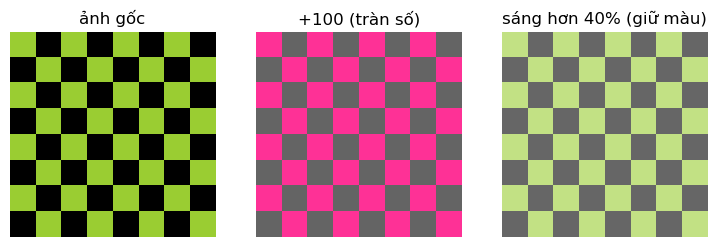

In [21]:
board = np.zeros((8, 8, 3), dtype=np.uint8)            # bàn cờ ở Demo A
board[::2, ::2] = board[1::2, 1::2] = [154, 205, 50]

brighter = board + 100                                 # uint8: 205 + 100 = 305 -> 305 - 256 = 49
print("một điểm ảnh màu xanh:", board[0, 0], "->", brighter[0, 0])

# Làm sáng đúng cách: kéo mỗi kênh tiến về 255 thêm 40% khoảng cách còn lại.
# Tính bằng float64 để không tràn số; kết quả không bao giờ vượt quá 255 nên không cần clip.
board_f = board.astype(np.float64)
brighter_ok = (board_f + (255 - board_f) * 0.4).round().astype(np.uint8)
print("đã sửa              :", brighter_ok[0, 0])

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for axis, img, title in zip(ax, [board, brighter, brighter_ok], ["ảnh gốc", "+100 (tràn số)", "sáng hơn 40% (giữ màu)"]):
    axis.imshow(img); axis.set_title(title); axis.axis("off")

In [ ]:
# Tiền lưu bằng int32: doanh thu 2,1 tỉ đồng, nhân đôi -> vượt quá giới hạn int32 -> tràn số
revenue = np.array([2_100_000_000], dtype=np.int32)
print("int32:", revenue * 2)
print("int64:", revenue.astype(np.int64) * 2)
print("int32 max:", np.iinfo(np.int32).max, "| int64 max:", np.iinfo(np.int64).max)

`float32` tiết kiệm một nửa bộ nhớ (hay dùng trong deep learning) nhưng chỉ có khoảng 7 chữ số có nghĩa:

In [ ]:
print(np.float32(16_777_217))           # 2**24 + 1 không lưu được
print(np.float64(16_777_217))

tenths32 = np.full(1_000_000, 0.1, dtype=np.float32).cumsum()   # tổng cộng dồn, giống số dư tài khoản
tenths64 = np.full(1_000_000, 0.1, dtype=np.float64).cumsum()
print("tổng cộng dồn 1 triệu lần 0.1 -> float32:", tenths32[-1], "| float64:", tenths64[-1])

### 3.7 NaN và inf

`nan` ("not a number") đánh dấu giá trị bị thiếu hoặc không xác định. Nó **lan truyền** qua các phép tính và **không bằng bất kỳ giá trị nào**, kể cả chính nó.

In [ ]:
x = np.array([5.0, np.nan, 3.0])
print("nan == nan     :", np.nan == np.nan)
print("x == np.nan    :", x == np.nan)            # không bao giờ tìm ra NaN!
print("np.isnan(x)    :", np.isnan(x))            # cách đúng
print("mean / nanmean :", x.mean(), "/", np.nanmean(x))
print("max / nanmax   :", x.max(), "/", np.nanmax(x))
print("argmax         :", x.argmax(), "(trỏ vào NaN)")

with np.errstate(divide="ignore", invalid="ignore"):
    print("1/0, -1/0, 0/0 :", np.array([1.0, -1.0, 0.0]) / 0)

Pandas dùng `NaN` cho giá trị bị thiếu, nên các quy tắc này sẽ gặp lại vào tuần sau.

### 3.8 Softmax: tràn số, và cách sửa chỉ một dòng

Softmax biến các điểm số thành xác suất: $\text{softmax}(z)_i = e^{z_i} / \sum_j e^{z_j}$. Phiên bản trong notebook gốc:

In [ ]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

small_scores = np.array([2.0, 1.0, 0.1])     # điểm số nhỏ: ổn
p = softmax_naive(small_scores)
print("điểm số nhỏ :", p, "| tổng =", p.sum())

scores = np.array([800.0, 801.0, 802.0])     # ví dụ: logit từ một mô hình
with np.errstate(over="ignore", invalid="ignore"):
    print("điểm số lớn :", softmax_naive(scores))      # exp(800) = inf -> inf/inf = nan

Trừ cùng một hằng số khỏi mọi điểm số không làm thay đổi softmax (hằng số bị triệt tiêu ở tử và mẫu). Trừ đi **giá trị lớn nhất**: số mũ lớn nhất trở thành $e^0 = 1$, nên không còn tràn số.

In [ ]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

print(softmax(scores))
print("giống bản naive khi đầu vào an toàn?", 
      np.allclose(softmax(small_scores), softmax_naive(small_scores)))

### 3.9 Quy tắc cần nhớ

| Tình huống | Nên làm |
|---|---|
| so sánh số thực | `np.isclose` / `np.allclose` với sai số cho phép chọn theo dữ liệu |
| tiền | số đồng nguyên (`int64`); làm tròn một lần, ngay ở đầu vào |
| đổi số thực → số nguyên | `round` (hoặc `np.rint`), không dùng `int()` |
| phương sai, khoảng cách | đưa dữ liệu về tâm trước; dùng hàm của thư viện |
| ảnh / số nguyên nhỏ | ép lên kiểu lớn hơn (`int16`, `int64`) trước khi tính, rồi `clip` |
| giá trị bị thiếu | `np.isnan`, các hàm `nan*`; không bao giờ dùng `== np.nan` |
| hàm mũ | trừ giá trị lớn nhất (softmax, log-sum-exp) |

## 4. Áp dụng Numpy để làm một ví dụ thực tế: recommender system 

Trong phần này, chúng ta sẽ xây dựng một hệ thống gợi ý phim đơn giản sử dụng **Collaborative Filtering** (lọc cộng tác).

### Ý tưởng chính:
1. 🔍 Tìm những người dùng có sở thích tương tự
2. 📊 Dự đoán điểm số cho các phim chưa xem
3. 🎬 Gợi ý những phim có điểm dự đoán cao nhất

### Phần 1: Đọc và Khám Phá Dữ Liệu

#### Cấu trúc file CSV:
- **Dòng đầu**: Tên các bộ phim
- **Mỗi cột**: Một bộ phim
- **Mỗi dòng**: Một người dùng
- **Giá trị**: Rating từ 1-5, hoặc NaN (chưa xem)

In [ ]:
# Đọc dữ liệu
ratings = np.genfromtxt('Data/Ratings-Small.csv',
                        delimiter=',',
                        skip_header=1)

# Đọc tên phim
with open('Data/Ratings-Small.csv', 'r', encoding='utf-8') as f:
    movie_names = f.readline().strip().split(',')

print(f"📊 Kích thước dữ liệu: {ratings.shape}")
print(f"   - {ratings.shape[0]} người dùng")
print(f"   - {ratings.shape[1]} bộ phim")
print(f"\n🎬 Danh sách phim: {movie_names}")

In [ ]:
# Hiển thị ma trận ratings
print("Ma trận Ratings:")
print(ratings)

In [ ]:
# Tính các thống kê
total_ratings = np.sum(~np.isnan(ratings))
total_possible = ratings.size
sparsity = (1 - total_ratings / total_possible) * 100

print("📈 Thống kê:")
print(f"   • Tổng ratings có sẵn: {total_ratings}/{total_possible}")
print(f"   • Độ thưa (sparsity): {sparsity:.1f}%")
print(f"   • Điểm trung bình: {np.nanmean(ratings):.2f}")
print(f"   • Điểm cao nhất: {np.nanmax(ratings):.0f}")
print(f"   • Điểm thấp nhất: {np.nanmin(ratings):.0f}")

### Phần 2: Dự Đoán Ratings cho Người Dùng 0

Chúng ta sẽ tập trung dự đoán ratings cho người dùng đầu tiên (index 0).

In [ ]:
# Chọn người dùng mục tiêu
target_user_idx = 0
r0 = ratings[target_user_idx]

print(f"Ratings của người dùng {target_user_idx}:")
for movie, rating in zip(movie_names, r0):
    if np.isnan(rating):
        print(f"   {movie:15s}: ❓ Chưa xem")
    else:
        print(f"   {movie:15s}: {'⭐' * int(rating)} ({rating:.0f} sao)")

In [ ]:
# Hiển thị tên các phim (người dùng 0) chưa xem
unseen_mask = np.isnan(r0)
unseen_indices = np.where(unseen_mask)[0]

print(f"\nCác phim cần dự đoán ({np.sum(unseen_mask)} phim):")
for idx in unseen_indices:
    print(f"   • {movie_names[idx]}")

#### Bước 1: Tính Độ Tương Tự

Chúng ta sử dụng **khoảng cách Manhattan đảo ngược** để tính độ tương tự:

$$
\text{similarity}(u_i, u_0) = \frac{1}{\text{mean}(|r_i - r_0|) + \epsilon}
$$

Trong đó:
- $r_i$: vector ratings của user $i$
- $r_0$: vector ratings của user target
- $\epsilon = 0.1$: tránh chia cho 0

In [ ]:
# Tính sự khác biệt tuyệt đối
differences = np.abs(ratings - r0)

print("Ma trận sự khác biệt (absolute differences):")
print(differences)

# Tính trung bình (bỏ qua NaN)
mean_diffs = np.nanmean(differences, axis=1)

print("\n📏 Trung bình sự khác biệt:")
for i, diff in enumerate(mean_diffs):
    print(f"   User {i}: {diff:.3f}")

In [ ]:
# Tính trọng số (weights)
epsilon = 0.1
weights = 1 / (mean_diffs + epsilon)

print("Trọng số (độ tương tự):")
for i, w in enumerate(weights):
    print(f"   User {i}: {w:8.3f}")

print("Giải thích:")
print("   • Trọng số cao = người dùng tương tự")
print("   • User 0 có trọng số cao nhất (so với chính mình)")

#### Bước 2: Lọc Dữ Liệu

Chỉ giữ lại ratings của các phim mà User 0 chưa xem.

In [ ]:
# Lấy ratings cho phim chưa xem
ratings_unseen = ratings[:, unseen_mask]

print(f"Ma trận ratings (chỉ phim chưa xem):")
print(f"Shape: {ratings_unseen.shape}")
print(ratings_unseen)

print("\n→ Tên các phim:")
movies_unseen=[movie_names[i] for i in unseen_indices]
movies_unseen

#### Bước 3: Chuẩn Hóa Trọng Số

Mục tiêu: Đảm bảo tổng trọng số = 1 cho mỗi phim.

**Quy trình:**
1. Tạo mask: giữ trọng số của users có rating
2. Chia mỗi trọng số cho tổng của cột

In [ ]:
# Bước 1: Mask users có rating
has_rating_mask = ~np.isnan(ratings_unseen)

print("Mask (1 = có rating, 0 = không có):")
print(has_rating_mask.astype(int))

In [ ]:
# Bước 2: Áp dụng mask
normalized_weights = has_rating_mask * weights.reshape(-1, 1)

print("Trọng số sau mask:")
print(normalized_weights)

In [ ]:
# Bước 3: Chuẩn hóa
normalized_weights = normalized_weights / normalized_weights.sum(axis=0)

print("Trọng số sau chuẩn hóa:")
print(normalized_weights)

print("\nKiểm tra: Tổng mỗi cột ==", normalized_weights.sum(axis=0))

#### Bước 4: Dự Đoán Ratings

Sử dụng công thức **weighted average**:

$$
\hat{r}_{0,j} = \sum_{i=1}^{n} w_i \cdot r_{i,j}
$$

Trong đó:
- $\hat{r}_{0,j}$: điểm dự đoán của user 0 cho phim $j$
- $w_i$: trọng số đã chuẩn hóa của user $i$
- $r_{i,j}$: rating của user $i$ cho phim $j$

In [ ]:
# Nhân ratings với trọng số
weighted_ratings = ratings_unseen * normalized_weights

print("Ma trận ratings × normalized_weights:")
print(weighted_ratings)

In [ ]:
# Cộng theo cột (bỏ qua NaN)
predicted_ratings = np.nansum(weighted_ratings, axis=0)

print("🎯 Dự đoán ratings:")
print(predicted_ratings)

### Phần 3: Kết Quả và Gợi Ý

In [ ]:
# Tạo danh sách kết quả
results = []
for i, idx in enumerate(unseen_indices):
    results.append({
        'movie': movie_names[idx],
        'prediction': predicted_ratings[i],
        'stars': '⭐' * int(round(predicted_ratings[i]))
    })

# Sắp xếp theo điểm giảm dần
results_sorted = sorted(results, key=lambda x: x['prediction'], reverse=True)

print("DANH SÁCH PHIM GỢI Ý (theo thứ tự ưu tiên):")

# Hiển thị bảng kết quả
print(f"{'STT':<5} {'Phim':<20} {'Dự đoán':<10} {'Đánh giá'}")
print("-" * 60)
for i, result in enumerate(results_sorted, start=1):
    print(f"{i:<5} {result['movie']:<20} {result['prediction']:<10.2f} {result['stars']}")

print(f"\n✨ Kết luận:")
print(f"   → Nên recommend: {results_sorted[0]['movie']}")
print(f"   → Điểm dự đoán: {results_sorted[0]['prediction']:.2f}/5.0")